# PEM Fuel Cell System for a Small Boat: Design Model and Operating-Point Study

A Python version of the Excel design model in [`../excel/fuel_cell_boat_design.xlsx`](../excel/fuel_cell_boat_design.xlsx).
The notebook reproduces the spreadsheet, examines how the stack's waste heat is used, and studies how the choice of
operating cell voltage trades stack size against hydrogen consumption and efficiency.

**Design basis.** A 4.8 m × 2 m two-person boat, 13–15 km/h, after a demonstrated 2 kW PEM fuel cell boat
(Tang et al., 2006). The system is a **2 kW, 24 V** stack at **80 °C** and **5 psig**, with dry hydrogen in dead-end
mode and humidified air (oxygen stoichiometry 2.5). The ancillary equipment is an air compressor, a humidifier, a
cathode-exhaust expander, a hydrogen pre-heater and pumps (see the flowsheet in the README).

Equations follow Barbir, *PEM Fuel Cells: Theory and Practice* (2nd ed., 2012). Enthalpies are referenced to 0 °C
and use the higher heating value of hydrogen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
F = 96485.0
M = dict(H2=2.0158, O2=31.9988, H2O=18.0152, N2=28.0134, air=28.848)        # g/mol
cp = dict(H2=14.2, O2=0.913, N2=1.04, air=1.01, vap=1.87, liq=4.16)           # J/(g K)
HHV_H2, h_fg = 141900.0, 2500.0                                               # J/g

def p_sat(T_K):
    # water saturation pressure (Pa), the correlation used in the spreadsheet (Barbir)
    return np.exp(-5800.2206 / T_K + 1.3914993 - 0.048640239 * T_K + 0.41764768e-4 * T_K**2
                  - 0.14452093e-7 * T_K**3 + 6.5459673 * np.log(T_K))

## 1. The design model

`design()` follows the spreadsheet step by step: stack sizing, the stack mass and energy balances, then the ancillary
equipment. The heating duties (humidifier and hydrogen pre-heater) are supplied from the stack coolant. Electric
heating is only needed if they exceed the stack's waste heat.

In [2]:
def design(V_cell=0.7, i_mA=740.0, W_stack=2000.0, V_stack=24.0, T_C=80.0, P=135798.79, T_amb=20.0,
           P_amb=101325.0, S_O2=2.5, S_H2=1.0, r_O2=0.21, RH_amb=0.63, eta_comp=0.75, eta_exp=0.75, k=1.4,
           eta_pump=0.85, head=0.5, dT_cm=7.5):
    T = T_C + 273.15
    r = {}
    # --- stack sizing
    I = W_stack / V_stack
    A_cell = I / (i_mA * 10)                    # m^2  (mA/cm^2 -> A/m^2 is x10)
    N = int(np.ceil(V_stack / V_cell))
    r.update(I=I, A_cell_cm2=A_cell * 1e4, N_cell=N, eta_stack=V_cell / 1.482 / S_H2)
    # --- mass balance (g/s)
    IN = I * N
    Pvs = p_sat(T)
    m = dict(H2_in=S_H2 * M["H2"] * IN / (2 * F), O2_in=S_O2 * M["O2"] * IN / (4 * F),
             air_in=S_O2 * M["air"] * IN / (4 * F * r_O2), N2_in=S_O2 * M["N2"] * (1 - r_O2) * IN / (4 * F * r_O2),
             H2O_air_in=S_O2 * M["H2O"] * Pvs * IN / (4 * F * r_O2 * (P - Pvs)),
             O2_cons=M["O2"] * IN / (4 * F), H2O_gen=M["H2O"] * IN / (2 * F))
    m["O2_out"] = m["O2_in"] - m["O2_cons"]
    m["air_out"] = m["O2_out"] + m["N2_in"]
    m["H2O_out"] = m["H2O_air_in"] + m["H2O_gen"]
    P_out = 0.9 * P
    vap_cap = (S_O2 - r_O2) * M["H2O"] * IN * Pvs / (r_O2 * 4 * F * (P_out - Pvs))
    m["H2O_out_vap"] = min(m["H2O_out"], vap_cap)
    m["H2O_out_liq"] = m["H2O_out"] - m["H2O_out_vap"]
    r["m"] = m
    # --- stack energy balance (W); inlet streams at stack temperature
    H_in = m["H2_in"] * (cp["H2"] * T_C + HHV_H2) + m["air_in"] * cp["air"] * T_C \
        + m["H2O_air_in"] * (cp["vap"] * T_C + h_fg)
    H_out = m["air_out"] * cp["air"] * T_C + m["H2O_out_vap"] * (cp["vap"] * T_C + h_fg) \
        + m["H2O_out_liq"] * cp["liq"] * T_C
    Q_cm = H_in - H_out - W_stack
    r.update(H_in=H_in, H_out=H_out, Q_stack=Q_cm, m_coolant=Q_cm / (cp["liq"] * dT_cm))
    # --- air compressor
    ratio = (P / P_amb) ** ((k - 1) / k)
    W_comp = m["air_in"] * cp["air"] * (T_amb + 273.15) * (ratio - 1) / eta_comp
    T_comp_out = T_amb + (T_amb + 273.15) / eta_comp * (ratio - 1)
    r.update(W_comp=W_comp, T_comp_out=T_comp_out)
    # --- humidifier: saturate the air at stack temperature
    # compression does not change the humidity ratio: it is set by ambient conditions
    x_in = M["H2O"] * RH_amb * p_sat(T_amb + 273.15) / (M["air"] * (P_amb - RH_amb * p_sat(T_amb + 273.15)))
    x_out = M["H2O"] * Pvs / (M["air"] * (P - Pvs))
    water = (x_out - x_in) * m["air_in"]
    H_air_in = m["air_in"] * (cp["air"] * T_comp_out + x_in * (cp["vap"] * T_comp_out + h_fg))
    H_air_out = m["air_in"] * (cp["air"] * T_C + x_out * (cp["vap"] * T_C + h_fg))
    Q_hum = H_air_out - water * cp["liq"] * T_C - H_air_in
    r.update(water_humidifier=water, Q_humidifier=Q_hum)
    # --- hydrogen pre-heater (HEX 1), 20 -> 80 C
    Q_pre = m["H2_in"] * cp["H2"] * (T_C - 20.0)
    r["Q_preheat"] = Q_pre
    # --- expander on the cathode exhaust
    T_exp_in = T
    dh = 1 - (P_amb / P_out) ** ((k - 1) / k)
    W_exp = m["air_out"] * cp["air"] * T_exp_in * dh * eta_exp
    r.update(W_exp=W_exp, T_exp_out=T_C - T_exp_in * dh * eta_exp)
    # --- pumps (mass flow in kg/s; rho only affects the volumetric flow)
    rho_sw = 1025.0
    sw_cool = Q_cm / (4.007 * 70)                              # seawater for the coolant loop, g/s
    sw_pre = Q_pre / (4.007 * 70)
    W_pumps = sum(mm / 1000 * head * 9.81 / eta_pump for mm in (sw_cool, sw_pre, water))
    r.update(W_pumps=W_pumps, V_seawater_cool=sw_cool / 1000 / rho_sw)
    # --- system
    # heating duties come from the stack coolant; electric heating only covers any shortfall
    heat_demand = Q_hum + Q_pre
    W_heat = max(0.0, heat_demand - Q_cm)
    r.update(heat_demand=heat_demand, W_heating=W_heat)
    W_aux = W_comp + W_pumps - W_exp + W_heat
    W_net = W_stack - W_aux
    r.update(W_aux=W_aux, W_net=W_net, eta_system=r["eta_stack"] * W_net / W_stack)
    return r

## 2. Check against the Excel model

In [3]:
d = design()
excel = dict(A_cell_cm2=112.6126, N_cell=35, eta_stack=0.4723347, Q_stack=2121.1921, W_comp=89.41546,
             T_comp_out=54.11048, Q_humidifier=2027.8506, Q_preheat=25.95877, W_exp=32.84099, heat_demand=2053.8093,
             W_aux=56.62352, W_net=1943.3765, eta_system=0.4589621)
check = pd.DataFrame({"Excel": excel, "Python": {k: d[k] for k in excel}})
check["rel. diff"] = (check.Python / check.Excel - 1).abs()
print(f"max relative difference: {check['rel. diff'].max():.1e}")
check.round(5)

max relative difference: 1.7e-07


,Excel,Python,rel. diff
A_cell_cm2,112.61260,112.61261,0.0
N_cell,35.00000,35.00000,0.0
eta_stack,0.47233,0.47233,0.0
Q_stack,2121.19210,2121.19206,0.0
W_comp,89.41546,89.41546,0.0
T_comp_out,54.11048,54.11048,0.0
Q_humidifier,2027.85060,2027.85057,0.0
Q_preheat,25.95877,25.95877,0.0
W_exp,32.84099,32.84099,0.0
heat_demand,2053.80930,2053.80934,0.0


In [4]:
mass = pd.Series(d["m"]).rename("g/s").round(4)
mass.to_frame()

,g/s
H2_in,0.0305
O2_in,0.6046
air_in,2.5954
N2_in,1.9910
H2O_air_in,0.8694
O2_cons,0.2418
H2O_gen,0.2723
O2_out,0.3627
air_out,2.3538
H2O_out,1.1417


Mass-balance checks: hydrogen in = hydrogen consumed (dead-end mode). The 0.27 g/s of product water leaves on the
cathode side; 0.94 g/s of water leaves as vapour (the exhaust's vapour capacity) and 0.20 g/s condenses, which the
water separator recovers for the humidifier.

## 3. Heat integration and system efficiency

In [5]:
print(f"heat needed for humidification + H2 pre-heating: {d['heat_demand']:.0f} W")
print(f"stack waste heat available:                     {d['Q_stack']:.0f} W ({100 * d['heat_demand'] / d['Q_stack']:.0f} % used)")
print(f"compressor {d['W_comp']:.1f} W, expander recovers {d['W_exp']:.1f} W, pumps {d['W_pumps']:.2f} W")
print(f"net power {d['W_net']:.0f} W, system efficiency (HHV) {100 * d['eta_system']:.1f} %")

heat needed for humidification + H2 pre-heating: 2054 W
stack waste heat available:                     2121 W (97 % used)
compressor 89.4 W, expander recovers 32.8 W, pumps 0.05 W
net power 1943 W, system efficiency (HHV) 45.9 %


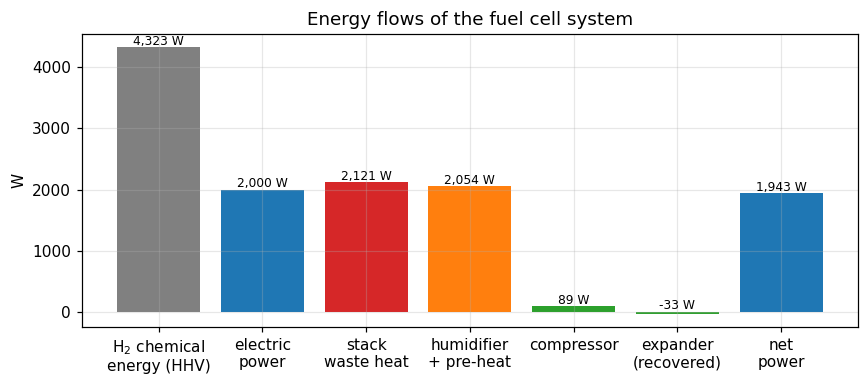

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = ["H$_2$ chemical\nenergy (HHV)", "electric\npower", "stack\nwaste heat", "humidifier\n+ pre-heat", "compressor", "expander\n(recovered)", "net\npower"]
H2_hhv = d["m"]["H2_in"] * HHV_H2
vals = [H2_hhv, 2000, d["Q_stack"], d["heat_demand"], d["W_comp"], -d["W_exp"], d["W_net"]]
cols = ["0.5", "C0", "C3", "C1", "C2", "C2", "C0"]
ax.bar(labels, vals, color=cols)
for x, v in enumerate(vals):
    ax.text(x, v + 40 if v > 0 else 40, f"{v:,.0f} W", ha="center", fontsize=8)
ax.set(ylabel="W", title="Energy flows of the fuel cell system")
fig.tight_layout()
fig.savefig("../figures/energy_flows.png", dpi=150, bbox_inches="tight")

- **The stack's waste heat almost exactly covers the heating duties.** Humidifying the air (which leaves the
  compressor at 54 °C) and pre-heating the hydrogen need about 2.05 kW. The stack rejects 2.12 kW. Routing the
  coolant through the humidifier water tank and the hydrogen pre-heater (see the flowsheet) means no electric
  heating is required.
- **Expander and compressor.** The expander recovers about 33 W of the compressor's 89 W. At 5 psig there is little
  pressure energy to recover, so the low-pressure design keeps the compressor parasitic load small instead.
- **Net result.** The net output is about 1.94 kW at a system efficiency of about 46 % (HHV basis).

## 4. Operating point: how should the cell voltage be chosen?

The project picked V_cell = 0.7 V, at 740 mA/cm² on the reference stack's polarization curve. The points below are
digitized approximately from that published curve and fitted with the standard semi-empirical model:
$V = E_0 - b\log_{10}(i) - R\,i - m\,e^{n i}$.

In [7]:
i_pts = np.array([45, 90, 130, 175, 215, 260, 305, 345, 390, 435, 475, 500, 520, 565, 605, 650, 690,
                  735, 780, 820, 865, 910, 950, 995, 1040, 1080, 1125, 1170], float)          # mA/cm^2
V_pts = np.array([0.872, 0.853, 0.840, 0.828, 0.815, 0.808, 0.795, 0.787, 0.778, 0.767, 0.757, 0.755, 0.752,
                  0.742, 0.735, 0.725, 0.719, 0.705, 0.698, 0.685, 0.675, 0.663, 0.650, 0.636, 0.622, 0.607,
                  0.586, 0.569])
from scipy.optimize import curve_fit
model = lambda i, E0, b, R, m, n: E0 - b * np.log10(i) - R * i - m * np.exp(n * i)
p, _ = curve_fit(model, i_pts, V_pts, p0=[0.98, 0.05, 1e-4, 1e-4, 4e-3], maxfev=20000)
rmse = np.sqrt(np.mean((model(i_pts, *p) - V_pts) ** 2))
print("fit: E0=%.3f V, b=%.3f V/decade, R=%.2e V cm2/mA, m=%.1e V, n=%.2e cm2/mA;  RMSE %.1f mV" % (*p, 1000 * rmse))
i_of_V = lambda V: __import__("scipy.optimize", fromlist=["brentq"]).brentq(lambda i: model(i, *p) - V, 20, 1200)
print(f"current density at 0.70 V from the fit: {i_of_V(0.70):.0f} mA/cm2 (project read 740)")

fit: E0=0.959 V, b=0.048 V/decade, R=1.38e-04 V cm2/mA, m=8.0e-04 V, n=3.97e-03 cm2/mA;  RMSE 1.4 mV
current density at 0.70 V from the fit: 761 mA/cm2 (project read 740)


,i_mA_cm2,N_cell,A_cell_cm2,active_area_m2,H2_g_per_h,eta_stack,eta_system,W_net
V_cell,,,,,,,,
0.600,1096.818,40,75.977,0.304,125.354,0.405,0.392,1935.282
0.625,1030.371,39,80.877,0.315,122.220,0.422,0.408,1936.901
0.650,953.110,37,87.433,0.324,115.953,0.439,0.425,1940.139
0.675,863.603,36,96.495,0.347,112.819,0.455,0.442,1941.757
0.700,761.441,35,109.442,0.383,109.685,0.472,0.459,1943.376
0.725,648.077,34,128.586,0.437,106.551,0.489,0.476,1944.995
0.750,527.195,32,158.069,0.506,100.283,0.506,0.465,1838.412
0.775,404.289,31,206.123,0.639,97.150,0.523,0.466,1780.963
0.800,286.051,30,291.323,0.874,94.016,0.540,0.465,1723.514


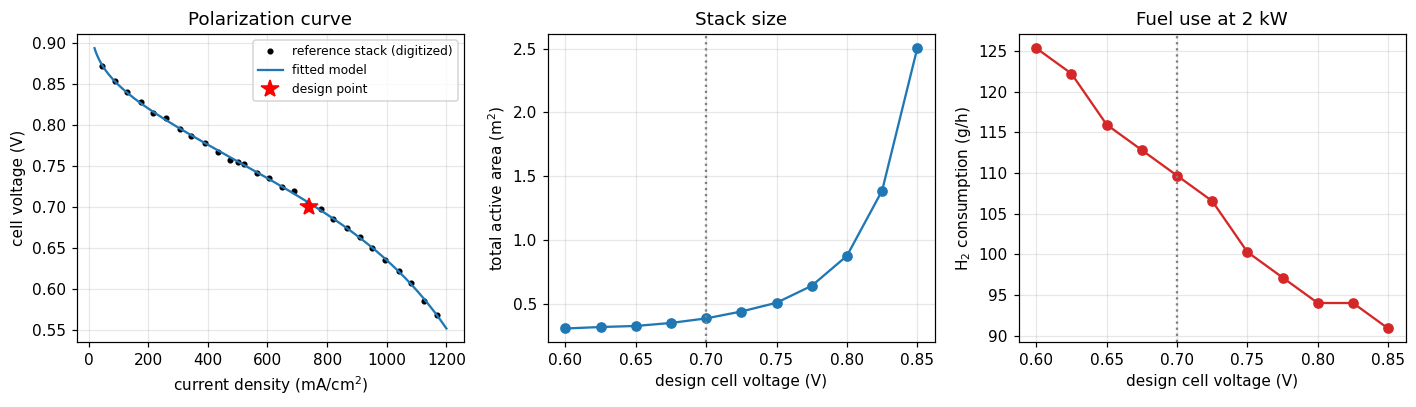

In [8]:
rows = []
for V in np.arange(0.60, 0.851, 0.025):
    i = i_of_V(V)
    dd = design(V_cell=V, i_mA=i)
    rows.append(dict(V_cell=V, i_mA_cm2=i, N_cell=dd["N_cell"], A_cell_cm2=dd["A_cell_cm2"],
                     active_area_m2=dd["N_cell"] * dd["A_cell_cm2"] / 1e4, H2_g_per_h=dd["m"]["H2_in"] * 3600,
                     eta_stack=dd["eta_stack"], eta_system=dd["eta_system"], W_net=dd["W_net"]))
op = pd.DataFrame(rows).set_index("V_cell")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
ii = np.linspace(20, 1200, 300)
axs[0].plot(i_pts, V_pts, "ko", ms=3, label="reference stack (digitized)")
axs[0].plot(ii, model(ii, *p), "C0", label="fitted model")
axs[0].plot(740, 0.7, "r*", ms=12, label="design point")
axs[0].set(xlabel="current density (mA/cm$^2$)", ylabel="cell voltage (V)", title="Polarization curve")
axs[0].legend(fontsize=8)
axs[1].plot(op.index, op.active_area_m2, "o-")
axs[1].set(xlabel="design cell voltage (V)", ylabel="total active area (m$^2$)", title="Stack size")
axs[2].plot(op.index, op.H2_g_per_h, "o-", color="C3")
axs[2].set(xlabel="design cell voltage (V)", ylabel="H$_2$ consumption (g/h)", title="Fuel use at 2 kW")
for ax in axs[1:]:
    ax.axvline(0.7, color="0.5", ls=":")
fig.tight_layout()
fig.savefig("../figures/operating_point.png", dpi=150, bbox_inches="tight")
op.round(3)

- **Higher cell voltage means a more efficient but bigger stack.** Every PEM design faces this trade-off.
  - Moving from 0.70 V to 0.80 V raises stack efficiency from 47 % to 54 % and cuts hydrogen use by 14 %.
  - It also needs 2.3 times the active area, because the current density drops steeply on the flat part of the curve.
  - Going down to 0.60 V shrinks the stack by about 21 %, but burns 14 % more hydrogen.
- **System efficiency peaks at about 0.725 V (47.6 %).** A more efficient stack also rejects less heat. Above about
  0.73 V, the waste heat no longer covers humidification and hydrogen pre-heating, so part of it must be supplied
  electrically. The system efficiency then stalls at about 46–48 %, while the stack keeps growing.
- **The project's 0.70 V choice is therefore well placed.** It is close to the system-efficiency optimum, keeps the
  stack compact, and sits in the near-linear (ohmic) part of the polarization curve, before the mass-transport losses
  above about 1000 mA/cm².
- **Hydrogen storage.** At the design point, the system uses about 110 g of H₂ per hour at full power. A 4-hour
  outing therefore needs about 0.44 kg of hydrogen, roughly 30 L of tank volume at the specified 200 bar (about
  15 g/L), plus the tank itself. Storage, not the stack, is likely to dominate the volume budget on a 4.8 m boat.